In [2]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

Path("outputs/plots").mkdir(parents=True, exist_ok=True)
df = pd.read_csv("data/manifest.csv")
print(df.shape)
df.head()

(3706, 3)


,filepath,label,split
0,data/raw/Anthracnose/20211008_124249 (Custom).jpg,Anthracnose,train
1,data/raw/Anthracnose/20211008_124250 (Custom).jpg,Anthracnose,test
2,data/raw/Anthracnose/20211008_124252 (Custom).jpg,Anthracnose,train
3,data/raw/Anthracnose/20211008_124253 (Custom).jpg,Anthracnose,train
4,data/raw/Anthracnose/20211008_124256 (Custom).jpg,Anthracnose,val


split             train  val  test
label                             
Anthracnose         337   72    72
Bacterial Canker    347   74    75
Cutting Weevil      172   37    37
Die Back            343   74    73
Gall Midge          347   74    75
Healthy             350   75    75
Powdery Mildew      349   75    74
Sooty Mould         349   75    75 



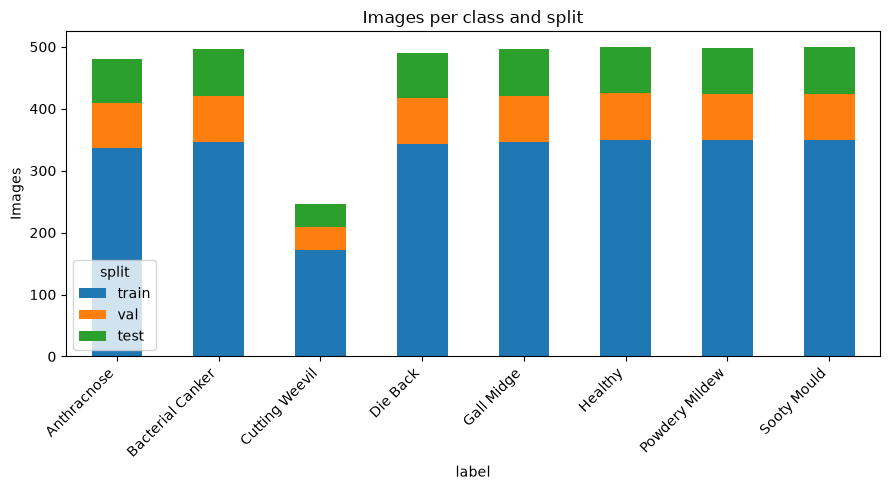

In [3]:
counts = pd.crosstab(df["label"], df["split"])[["train", "val", "test"]]
print(counts, "\n")

ax = counts.plot(kind="bar", stacked=True, figsize=(9, 5))
ax.set_title("Images per class and split")
ax.set_ylabel("Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("outputs/plots/class_distribution.png", dpi=150)
plt.show()

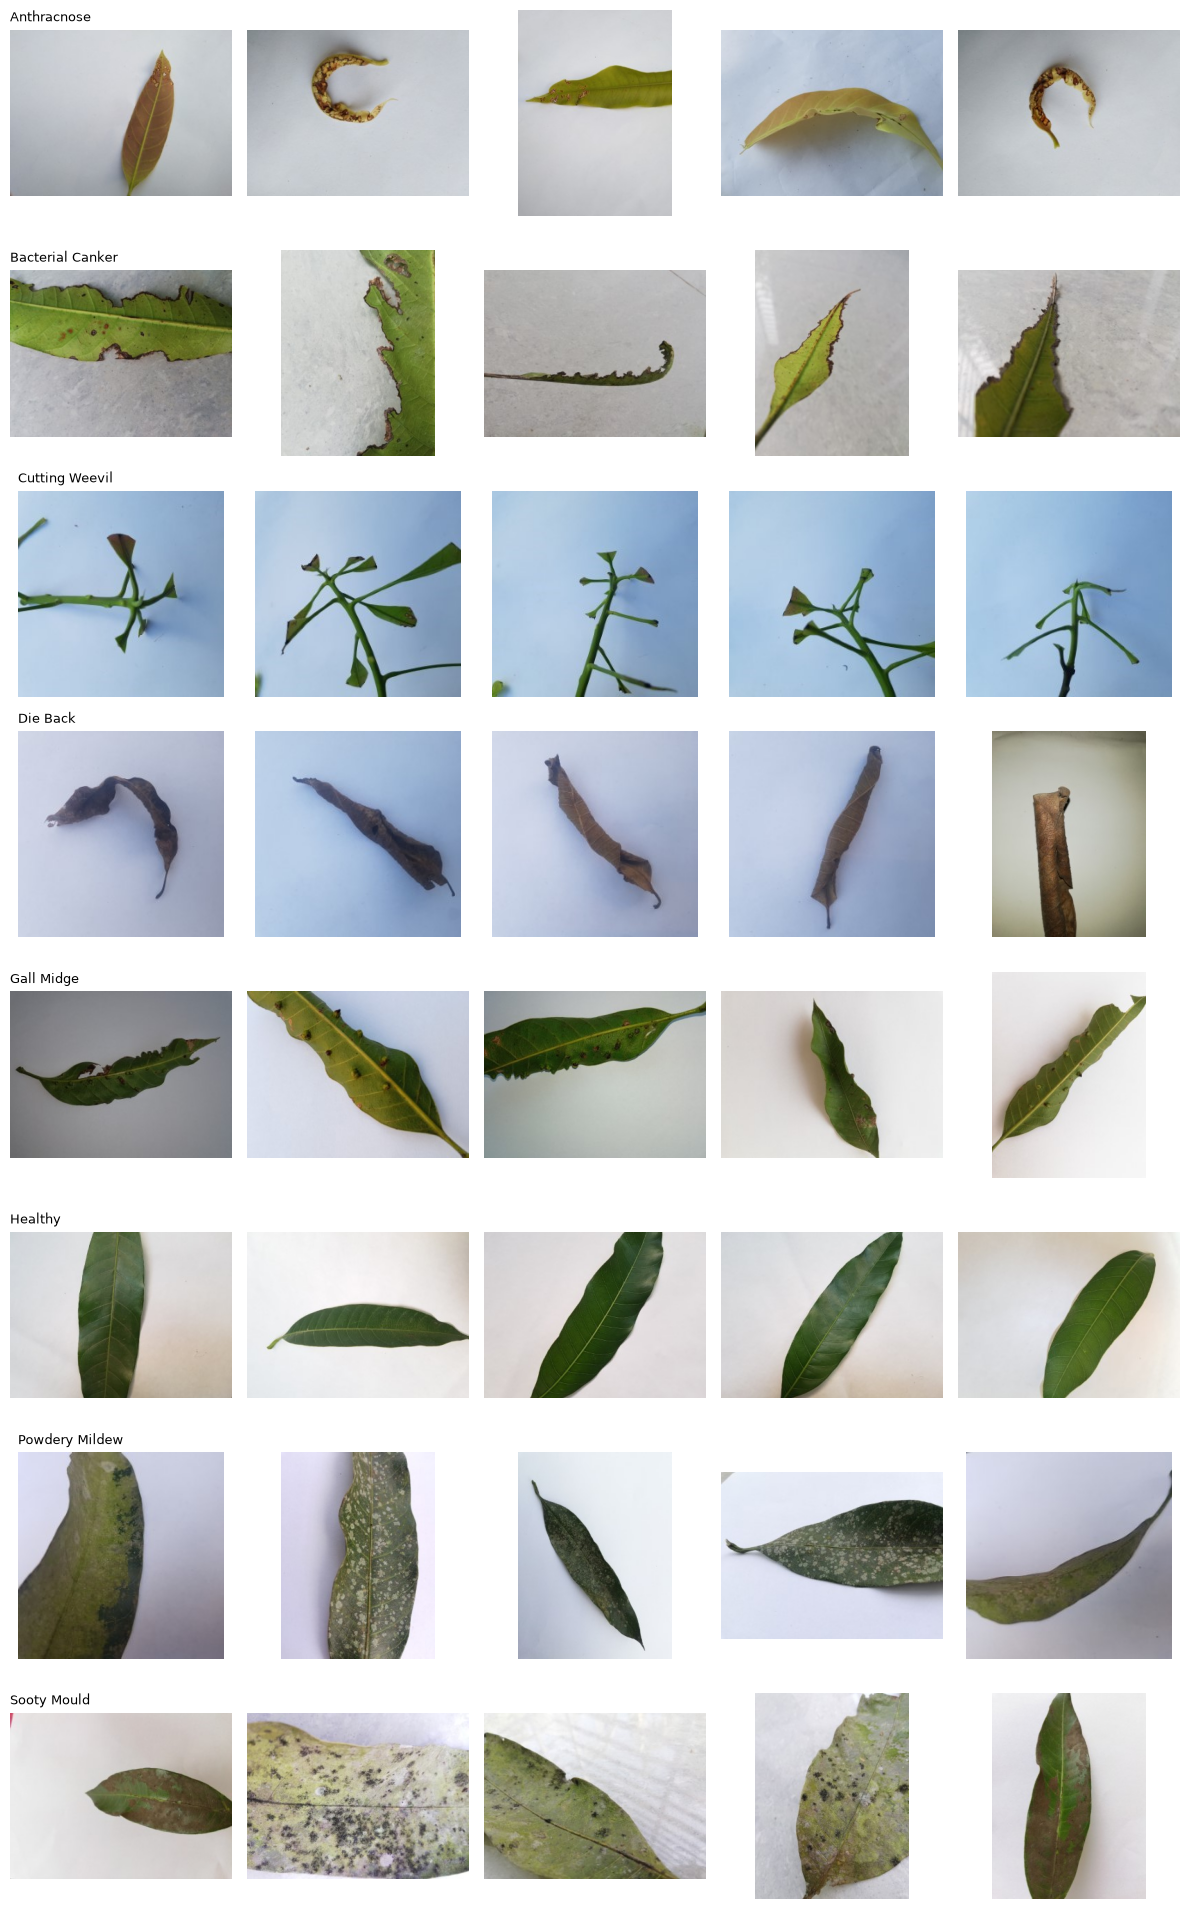

In [4]:
classes = sorted(df["label"].unique())
n = 5
fig, axes = plt.subplots(len(classes), n, figsize=(n * 2.4, len(classes) * 2.4))
rng = np.random.default_rng(42)

for r, c in enumerate(classes):
    paths = df[df["label"] == c]["filepath"].values
    for k, p in enumerate(rng.choice(paths, n, replace=False)):
        axes[r, k].imshow(Image.open(p).convert("RGB"))
        axes[r, k].axis("off")
    axes[r, 0].set_title(c, fontsize=9, loc="left")

plt.tight_layout()
plt.savefig("outputs/plots/sample_grid.png", dpi=150)
plt.show()

In [5]:
sizes = []
for p in df["filepath"]:
    with Image.open(p) as im:
        sizes.append(im.size)          # (width, height)
df["width"] = [s[0] for s in sizes]
df["height"] = [s[1] for s in sizes]

print(df.groupby(["width", "height"]).size().sort_values(ascending=False).head(10))
print(df.groupby("label")[["width", "height"]].agg(["min", "max"]))

width  height
320    240       1653
240    320       1010
       240        916
320    220          5
       226          4
       228          4
       195          3
       229          3
       212          3
240    262          3
dtype: int64
                 width      height     
                   min  max    min  max
label                                  
Anthracnose        240  320     86  320
Bacterial Canker   240  320    240  320
Cutting Weevil     240  320    240  240
Die Back           240  320    240  320
Gall Midge         187  320     70  320
Healthy            210  320    160  320
Powdery Mildew     189  320    175  320
Sooty Mould        240  320    240  320


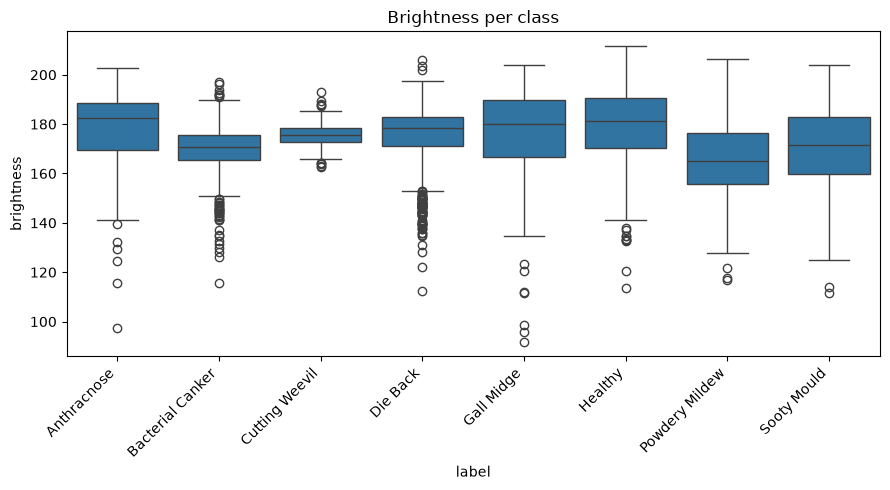

In [6]:
stats = []
for p in df["filepath"]:
    with Image.open(p) as im:
        a = np.asarray(im.convert("RGB").resize((64, 64)), dtype=np.float32)
    stats.append([a.mean(), *a.mean(axis=(0, 1))])
df[["brightness", "mean_r", "mean_g", "mean_b"]] = stats

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="label", y="brightness")
plt.xticks(rotation=45, ha="right")
plt.title("Brightness per class")
plt.tight_layout()
plt.savefig("outputs/plots/brightness_per_class.png", dpi=150)
plt.show()